# Parameterized Post-Einsteinian Phase Correction Tutorial

In this tutorial, we demonstrate the usage of the [`GWCorrect.ppE`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/index.html) submodule of this python package. You can download this tutorial [here](https://github.com/RyanSR71/GWCorrect/blob/main/docs/source/notebooks/ppE_Tutorial.ipynb).

The following cell is everything we need to import to run this tutorial. We also import the `GWCorrect` package, which will need to be installed first. See [Installation](https://waveformuncertainty.readthedocs.io/en/latest/installation.html#installation).

In [2]:
import os
import numpy as np
import bilby
import matplotlib.pyplot as plt
import lal
import requests
import GWCorrect
import GWCorrect.ppE as ppE

In [3]:
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'serif'

## ppE Correction Model

We will first demonstrate how to set up the ppE correction model. This process is very simple and only requires one modification to the default bilby waveform generator. [`GWCorrect.ppE.waveform_generator.ppECorrectionModel`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/waveform_generator/ppECorrectionModel.html) is a frequency domain source model, and can be placed into the bilby waveform generator as an argument.

In [4]:
waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                            catch_waveform_errors=True, minimum_frequency=20.0, maximum_frequency=2048.0)

ppE_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
                    waveform_arguments=waveform_arguments,
                    # we simply place the ppE correction model as the frequency_domain_source_model 
                    frequency_domain_source_model=ppE.waveform_generator.ppECorrectionModel,
                    sampling_frequency=4096, 
                    duration=16,
                )

08:37 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=16, sampling_frequency=4096, start_time=0, frequency_domain_source_model=GWCorrect.ppE.waveform_generator.ppECorrectionModel, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'reference_frequency': 20, 'catch_waveform_errors': True, 'minimum_frequency': 20.0, 'maximum_frequency': 2048.0})


That is all we had to do to set up the ppE correction model! To use this model, we need to make sure to add the new source parameters that the model calls.

These new parameters are: $\tilde\beta$, $\delta\tilde\epsilon$, and $b$. To see what these parameters do, we can plot the frequency domain phase differences with various draws of the parameters. First, we start by defining a default bilby waveform generator to serve as our baseline waveform. We also choose some binary black hole injection parameters.

In [5]:
waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                            catch_waveform_errors=True, minimum_frequency=20.0, maximum_frequency=2048.0)

GR_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
                    waveform_arguments=waveform_arguments,
                    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
                    sampling_frequency=4096, 
                    duration=16,
                )

# arbitrary binary black hole injection parameters
injection = dict(
    chirp_mass=17.4,
    mass_ratio=1,
    chi_1=0,
    chi_2=0,
    luminosity_distance=598,
    geocent_time=1126259462.4,
    phase=1.577,
    theta_jn=0.48736165
)

08:37 bilby INFO    : Waveform generator instantiated: WaveformGenerator(duration=16, sampling_frequency=4096, start_time=0, frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole, time_domain_source_model=None, parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters, waveform_arguments={'waveform_approximant': 'IMRPhenomD', 'reference_frequency': 20, 'catch_waveform_errors': True, 'minimum_frequency': 20.0, 'maximum_frequency': 2048.0})


Now we can use [`GWCorrect.wfu.parameterization.fd_model_difference`](https://waveformuncertainty.readthedocs.io/en/latest/wfu/parameterization/fd_model_difference.html) to help us find the phase differences created by the new parameters. First, we start with $\tilde\beta$. We fix $\delta\tilde\epsilon=0$ and $b=-1$.

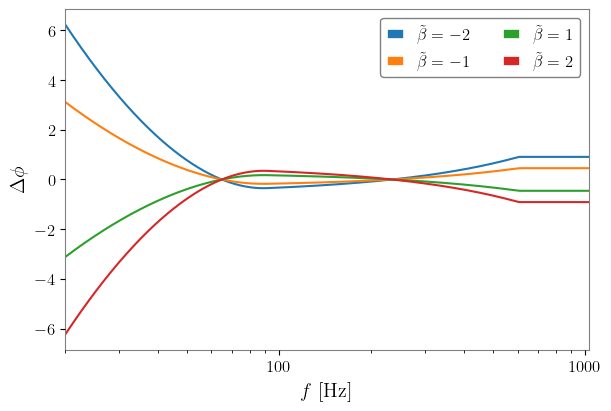

In [6]:
# adding the ppE parameters
injection['delta_epsilon_tilde'] = 0
injection['b'] = -1

fig, ax = plt.subplots(figsize=(6,4),layout='constrained')

for beta_tilde in [-2,-1,1,2]:
    
    injection['beta_tilde'] = beta_tilde
    
    frequency_grid, _, phase_difference = GWCorrect.wfu.parameterization.fd_model_difference(ppE_waveform_generator,GR_waveform_generator,
                                                                                             injection=injection)
    
    ax.semilogx(frequency_grid,phase_difference,label=r'$\tilde\beta=val$'.replace('val',str(beta_tilde)))
    
    
ax.set_xlim(20,1024)
ax.grid(False)
ax.set_xlabel(r'$f\ [\mathrm{Hz}]$')
ax.set_ylabel(r'$\Delta\phi$')
ax.legend(fancybox=True,framealpha=1,ncol=2)
plt.show()

We see that $\tilde\beta$ controls the magnitude of the ppE correction, where higher values create larger deviations from GR ($\tilde\beta=0$) in the early inspiral.

We can do this same analysis with $\delta\tilde\epsilon$, but this time, fixing $\tilde\beta=0$.

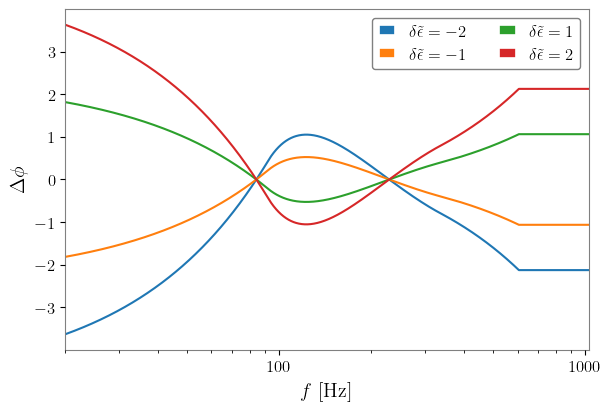

In [7]:
injection['beta_tilde'] = 0

fig, ax = plt.subplots(figsize=(6,4),layout='constrained')

for delta_epsilon_tilde in [-2,-1,1,2]:
    
    injection['delta_epsilon_tilde'] = delta_epsilon_tilde
    
    frequency_grid, _, phase_difference = GWCorrect.wfu.parameterization.fd_model_difference(ppE_waveform_generator,GR_waveform_generator,
                                                                                             injection=injection)
    
    ax.semilogx(frequency_grid,phase_difference,label=r'$\delta\tilde\epsilon=val$'.replace('val',str(delta_epsilon_tilde)))
    
ax.set_xlim(20,1024)
ax.grid(False)
ax.set_xlabel(r'$f\ [\mathrm{Hz}]$')
ax.set_ylabel(r'$\Delta\phi$')
ax.legend(fancybox=True,framealpha=1,ncol=2)
plt.show()

$\delta\tilde\epsilon$ together with $\tilde\beta$ define another parameter, $\epsilon$, which controls the merger time of the gravitational wave. This introduces a shift in the time domain that we see as these curves in the frequency domain.

Finally, we look at how $b$ affects the phase. $b$ has no effect on the waveform if $\tilde\beta$ and $\delta\tilde\epsilon$ are 0, so we choose to set $\tilde\beta=1$ and $\delta\tilde\epsilon=0$.

Note: $b=0$ and $b=3$ are invalid values for $b$. Both of these cause overall shifts in either time or phase, which are always excluded in parameter estimation.

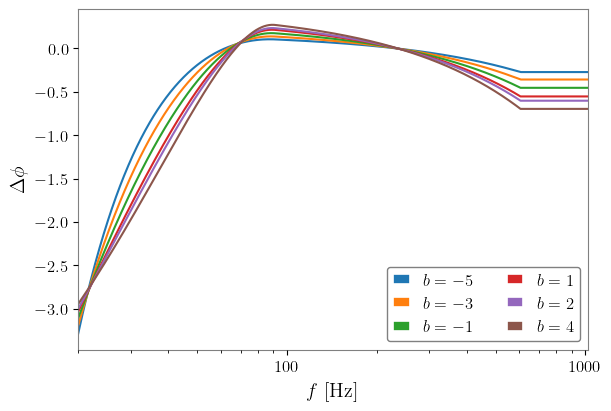

In [8]:
injection['beta_tilde'] = 1
injection['delta_epsilon_tilde'] = 0

fig, ax = plt.subplots(figsize=(6,4),layout='constrained')

for b in [-5,-3,-1,1,2,4]:
    
    injection['b'] = b
    
    frequency_grid, _, phase_difference = GWCorrect.wfu.parameterization.fd_model_difference(ppE_waveform_generator,GR_waveform_generator,
                                                                                             injection=injection)
    
    ax.semilogx(frequency_grid,phase_difference,label=r'$b=val$'.replace('val',str(b)))
    
ax.set_xlim(20,1024)
ax.grid(False)
ax.set_xlabel(r'$f\ [\mathrm{Hz}]$')
ax.set_ylabel(r'$\Delta\phi$')
ax.legend(fancybox=True,framealpha=1,ncol=2)
plt.show()

$b$ controls the post-Newtonian (PN) order of the ppE correction. The PN order can be found with $(b+5)/2$.

## Match

In this section, we look at the match functions in the [`GWCorrect.ppE.prior`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/prior/index.html) submodule, which are [`match`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/prior/match.html) and [`match_plot`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/prior/match_plot.html).

We can compute the normalized match between two waveforms. To demonstrate this, we look to calculate the match between a GR waveform and a ppE waveform with $\tilde\beta=1$, $\delta\tilde\epsilon=0$ and $b=-1$. We start by generating the two waveforms:

In [9]:
waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                            catch_waveform_errors=True, minimum_frequency=20.0, maximum_frequency=2048.0)

ppE_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
                    waveform_arguments=waveform_arguments,
                    # we simply place the ppE correction model as the frequency_domain_source_model 
                    frequency_domain_source_model=ppE.waveform_generator.ppECorrectionModel,
                    sampling_frequency=4096, 
                    duration=16,
                )

waveform_arguments = dict(waveform_approximant='IMRPhenomD', reference_frequency=20, 
                            catch_waveform_errors=True, minimum_frequency=20.0, maximum_frequency=2048.0)

GR_waveform_generator = bilby.gw.WaveformGenerator(parameter_conversion=bilby.gw.conversion.convert_to_lal_binary_black_hole_parameters,
                    waveform_arguments=waveform_arguments,
                    frequency_domain_source_model=bilby.gw.source.lal_binary_black_hole,
                    sampling_frequency=4096, 
                    duration=16,
                )

injection = dict(
    chirp_mass=17.4,
    mass_ratio=1,
    chi_1=0,
    chi_2=0,
    luminosity_distance=598,
    geocent_time=1126259462.4,
    phase=1.577,
    theta_jn=0.48736165,
    beta_tilde = 1,
    delta_epsilon_tilde = 0,
    b = -1
)

print(ppE.prior.match(ppE_waveform_generator,GR_waveform_generator,injection))

0.8139979904878409


To see how the match changes with $\tilde\beta$ and $\delta\tilde\epsilon$, we can use [`GWCorrect.ppE.prior.match_plot`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/prior/match_plot.html) to generate a contour plot:

Generating Contour Plot: 100%|██████████| 441/441 [00:39<00:00, 11.06it/s]


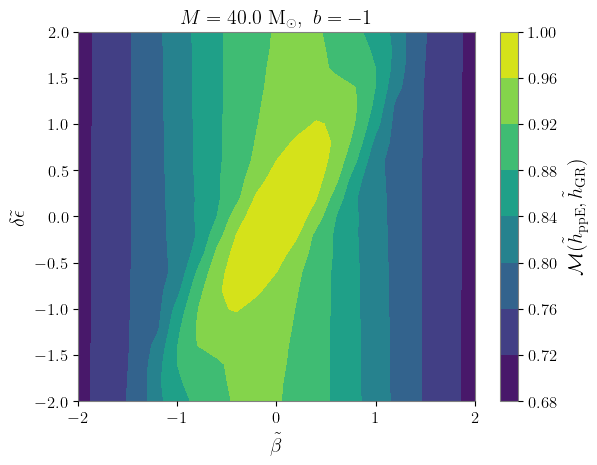

In [10]:
# choose a binary black hole injection
injection = dict(
    chirp_mass=17.4,
    mass_ratio=1,
    chi_1=0,
    chi_2=0,
    luminosity_distance=598,
    geocent_time=1126259462.4,
    phase=1.577,
    theta_jn=0.48736165
)

# include a b value
injection['b'] = -1

# choose beta_tilde and delta_epsilon values to sample and put them in arrays
beta_tildes = np.linspace(-2,2,21)
delta_epsilon_tildes = np.linspace(-2,2,21)

# creating a directory for the tutorial files
try:
    os.mkdir('tutorial_files')
except:
    pass

# creating the contour plot parameters
X, Y, match_grid = ppE.prior.match_plot(ppE_waveform_generator,GR_waveform_generator,injection,beta_tildes,delta_epsilon_tildes)

# creating the contour plot
plt.contourf(X,Y,match_grid)
plt.colorbar(label=r'$\mathcal{M}(\tilde{h}_\mathrm{ppE},\tilde{h}_\mathrm{GR})$')
plt.xlabel(r'$\tilde\beta$')
plt.ylabel(r'$\delta\tilde\epsilon$')
plt.title(r'$M=40.0\ \mathrm{M}_\odot,\ b=-1$')
plt.grid(False)

plt.show()

## Sampling and Posterior Analysis

To perform parameter estimation with the ppE waveform model, we simply need to make changes to a standard binary black hole prior.

First, we need to set up the total mass constraint. For the ppE model to work properly, we must enforce the condition $M<[Mf_\mathrm{IM}]c^3/Gf_\mathrm{low}$, where $[Mf_\mathrm{IM}]=0.018$ by default. To add this constraint to a bilby prior, we first add [`GWCorrect.ppE.prior.total_mass_conversion`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/prior/total_mass_conversion.html) as a conversion function in the bilby [`PriorDict`](https://bilby-dev.github.io/bilby/api/bilby.core.prior.dict.PriorDict.html#bilby.core.prior.dict.PriorDict) function. Then, we add the total mass prior as [`GWCorrect.ppE.prior.TotalMassConstraintPPE`](https://waveformuncertainty.readthedocs.io/en/latest/ppE/prior/TotalMassConstraintPPE.html). We include `minimum_frequency` as an argument, using the same minimum frequency that we put into the waveform generator.

Finally, we need to add priors for the ppE parameters: $\tilde\beta$, $\delta\tilde\epsilon$, and $b$. A full BBH+ppE prior is shown below:

In [11]:
prior = bilby.core.prior.PriorDict(conversion_function = ppE.prior.total_mass_conversion)

prior['total_mass'] = ppE.prior.TotalMassConstraintPPE(name='total_mass',latex_label=r'$M$',minimum_frequency=20,unit=r'$\mathrm{M}_{\odot}$')
prior['chirp_mass'] = bilby.gw.prior.UniformInComponentsChirpMass(name='chirp_mass',latex_label=r'$\mathcal{M}_c$',minimum=10,maximum=100,unit=r'$\mathrm{M}_{\odot}$')
prior['mass_ratio'] = bilby.gw.prior.UniformInComponentsMassRatio(name='mass_rato',latex_label=r'$q$',minimum=0.125,maximum=1)
prior['chi_1'] = bilby.gw.prior.AlignedSpin(name='chi_1',latex_label=r'$\chi_1$')
prior['chi_2'] = bilby.gw.prior.AlignedSpin(name='chi_2',latex_label=r'$\chi_2$')
prior['luminosity_distance'] = bilby.gw.prior.UniformSourceFrame(name='luminosity_distance',latex_label=r'$D_L$',minimum=10,maximum=1000,unit='Mpc')
prior['geocent_time'] = bilby.core.prior.Uniform(name='geocent_time',latex_label=r'$t_{c}$',minimum=1126259462.3,maximum=1126259462.5,unit='s')
prior['phase'] = bilby.core.prior.Uniform(name='phase',latex_label=r'$\phi_\mathrm{ref}$',minimum=0,maximum=2*np.pi,boundary='periodic')
prior['theta_jn'] = bilby.core.prior.Sine(name='theta_jn',latex_label=r'$\theta_{JN}$')

prior['beta_tilde'] = bilby.core.prior.Uniform(name='beta_tilde',latex_label=r'$\tilde{\beta}$',minimum=-2,maximum=2)
prior['delta_epsilon_tilde'] = bilby.core.prior.Uniform(name='delta_epsilon_tilde',latex_label=r'$\delta\tilde{\epsilon}$',minimum=-2,maximum=2)
prior['b'] = bilby.core.prior.Uniform(name='b',latex_label=r'$b$',minimum=-15,maximum=10)

Usually, we use a reduced prior where we assume an equal mass ratio and zero spins. In this case, we do not need to constrain the total mass with the constraint prior and instead limit the prior on the chirp mass to satisfy the total mass constraint.

Parameter estimation can then be performed normally. See [bilby's documentation](https://bilby-dev.github.io/bilby/visualising_the_results.html) for details.

The resulting posterior file will contain the posteriors for $\tilde\beta$, $\delta\tilde\epsilon$, and $b$. We can load in an example result file to examine it:

In [12]:
# downloading the file and saving to tutorial files folder
try:
    os.mkdir('tutorial_files')
except:
    pass
file = requests.get('https://github.com/RyanSR71/GWCorrect/raw/refs/heads/main/files/ppE_sample_result_file.json', allow_redirects=True)
open("tutorial_files/ppE_sample_result_file.json", 'wb').write(file.content)

# loading the file
result = bilby.read_in_result("tutorial_files/ppE_sample_result_file.json")

In [ ]:
# creating a corner plot
injection = dict(
    chirp_mass = 17.4,
    beta_tilde = 0.5,
    delta_epsilon_tilde = -0.25,
    b = -1
)

result.plot_corner(save=False,truth=injection)
plt.show()